# Section 2 – Supervised learning – Classification


In [1]:
import copy
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer
)

from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    StratifiedShuffleSplit,
    cross_validate,
    learning_curve,
    train_test_split,
    validation_curve
)

from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('ddos_dataset_pre_PCA.csv', dtype={'SimillarHTTP':str}, index_col=0)
df.columns = df.columns.str.strip()

In [ ]:
test_size=0.2 #Test size 30%

train_list = []
test_list = []

labels = df['label'].unique()

for label in labels:
    group = df[df['label'] == label]
    group = group.sort_values(by='Timestamp')
    
    n_samples = len(group)
    split_idx = int(n_samples * (1 - test_size))
    
    train_group = group.iloc[:split_idx]
    test_group = group.iloc[split_idx:]
    
    train_list.append(train_group)
    test_list.append(test_group)

train_df = pd.concat(train_list)
test_df = pd.concat(test_list)

# Concatenate and Shuffle
# We concat all the per-label chunks back into one big dataframe
train_df_temporal = pd.concat(train_list).reset_index(drop=True)
test_df_temporal = pd.concat(test_list).reset_index(drop=True)

# 3. Separate X and y
cols_to_drop = ['label', 'Timestamp'] 

# X matrices (Features)
X_train_temp = train_df_temporal.drop(columns=cols_to_drop, errors='ignore')
X_test_temp = test_df_temporal.drop(columns=cols_to_drop, errors='ignore')

# y vectors (Labels)
y_train = train_df_temporal['label']
y_test = test_df_temporal['label']

# checks
print(f"Training set size: {len(X_train_temp)} ({len(X_train_temp)/len(df)*100:.2f}%)")
print(f"Testing set size:  {len(X_test_temp)} ({len(X_test_temp)/len(df)*100:.2f}%)")

    

Training set size: 51386 (79.99%)
Testing set size:  12853 (20.01%)


In [4]:
# Columns that cannot be standardized
to_drop = ['Flow ID', 'Source IP', 'Destination IP', 'label', 'Timestamp', 'hour']

X_train_temp = X_train_temp.drop(columns=to_drop, errors='ignore')
X_test_temp = X_test_temp.drop(columns=to_drop, errors='ignore')

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_temp)
X_test = scaler.transform(X_test_temp)

# Random Forest classifier
## Training with deafult parameters

Test set
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      3960
    ddos_dns       1.00      1.00      1.00      3758
   ddos_ldap       1.00      1.00      1.00      4149
  ddos_mssql       1.00      1.00      1.00      4137
ddos_netbios       1.00      1.00      1.00      4080
    ddos_ntp       1.00      1.00      1.00       690
   ddos_snmp       1.00      1.00      1.00      4188
   ddos_ssdp       1.00      1.00      1.00      4179
    ddos_syn       1.00      1.00      1.00      3835
   ddos_tftp       1.00      1.00      1.00      3682
    ddos_udp       1.00      1.00      1.00      4113
ddos_udp_lag       1.00      1.00      1.00      4190

    accuracy                           1.00     44961
   macro avg       1.00      1.00      1.00     44961
weighted avg       1.00      1.00      1.00     44961



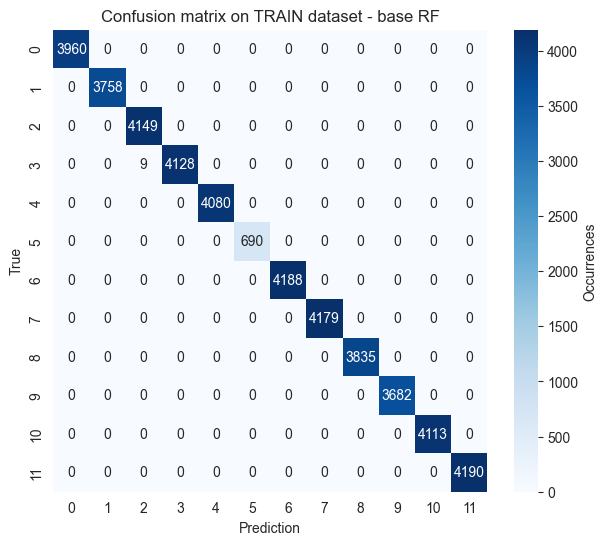

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_train = rf.predict(X_train)

print('Test set')
print(classification_report(y_train, y_pred_train))

confusion = confusion_matrix(y_train, y_pred_train)

plt.figure(figsize=(7,6))
sns.heatmap(confusion, cmap='Blues', annot=True, cbar_kws={'label':'Occurrences'}, fmt='d')
plt.xlabel('Prediction')
plt.ylabel('True')
plt.title('Confusion matrix on TRAIN dataset - base RF')
plt.show()

Test set
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      1698
    ddos_dns       0.73      0.99      0.84      1611
   ddos_ldap       0.81      0.71      0.76      1779
  ddos_mssql       0.74      0.84      0.79      1774
ddos_netbios       1.00      1.00      1.00      1750
    ddos_ntp       1.00      0.99      0.99       296
   ddos_snmp       1.00      0.67      0.81      1796
   ddos_ssdp       1.00      1.00      1.00      1791
    ddos_syn       0.90      0.80      0.85      1645
   ddos_tftp       0.81      0.90      0.86      1579
    ddos_udp       1.00      1.00      1.00      1763
ddos_udp_lag       1.00      1.00      1.00      1796

    accuracy                           0.90     19278
   macro avg       0.92      0.91      0.91     19278
weighted avg       0.91      0.90      0.90     19278



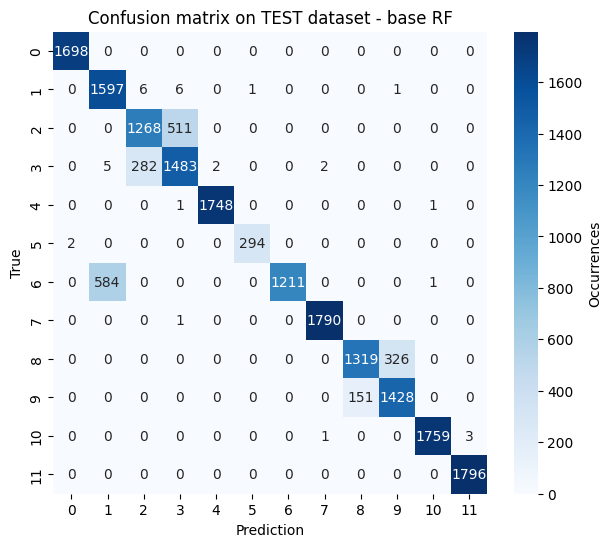

In [6]:


rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print('Test set')
print(classification_report(y_test, y_pred))

confusion = confusion_matrix(y_test, y_pred)

# visualize the confusion matrix
plt.figure(figsize=(7,6))
sns.heatmap(confusion, cmap='Blues', annot=True, cbar_kws={'label':'Occurrences'}, fmt='d')
plt.xlabel('Prediction')
plt.ylabel('True')
plt.title('Confusion matrix on TEST dataset - base RF')
plt.show()


# Validation Curve
Valdiation curve before the grid search allowing me to inspect the best possible values.

Calculating Validation Curve for Max Depth... (1/2)
Calculating Validation Curve for Min Samples Leaf... (2/2)


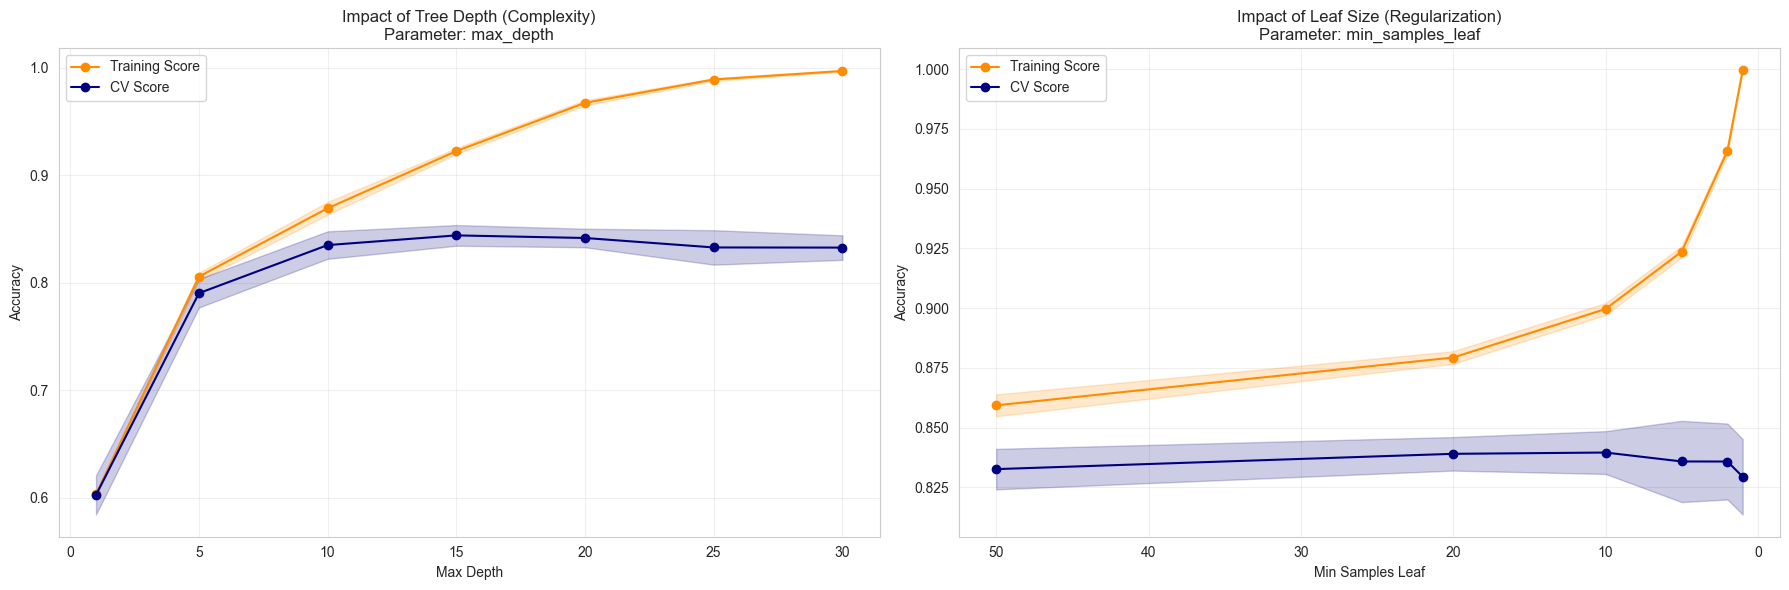

In [ ]:
# --- 1. Configuration of Ranges ---
# Range for Max Depth
param_range_depth = [1, 5, 10, 15, 20, 25, 30]

# Range for Min Samples Leaf
# Geometric progression to test exponentially larger constraints
param_range_leaf = [1, 2, 5, 10, 20, 50]

# Initialize Base Model
rf = RandomForestClassifier(n_estimators=50, random_state=42)

print("Calculating Validation Curve for Max Depth... (1/2)")
train_scores_depth, test_scores_depth = validation_curve(
    estimator=rf,
    X=X_train,
    y=y_train,
    param_name="max_depth",
    param_range=param_range_depth,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Calculating Validation Curve for Min Samples Leaf... (2/2)")
train_scores_leaf, test_scores_leaf = validation_curve(
    estimator=rf,
    X=X_train,
    y=y_train,
    param_name="min_samples_leaf",
    param_range=param_range_leaf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# --- 2. Statistical Processing (Mean & Std) ---
def get_stats(train_s, test_s):
    return (np.mean(train_s, axis=1), np.std(train_s, axis=1),
            np.mean(test_s, axis=1), np.std(test_s, axis=1))

train_mean_d, train_std_d, test_mean_d, test_std_d = get_stats(train_scores_depth, test_scores_depth)
train_mean_l, train_std_l, test_mean_l, test_std_l = get_stats(train_scores_leaf, test_scores_leaf)

# --- 3. Visualization (Side-by-Side Plots) ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Max Depth
axes[0].plot(param_range_depth, train_mean_d, label="Training Score", color="darkorange", marker='o')
axes[0].fill_between(param_range_depth, train_mean_d - train_std_d, train_mean_d + train_std_d, alpha=0.2, color="darkorange")
axes[0].plot(param_range_depth, test_mean_d, label="CV Score", color="navy", marker='o')
axes[0].fill_between(param_range_depth, test_mean_d - test_std_d, test_mean_d + test_std_d, alpha=0.2, color="navy")
axes[0].set_title("Impact of Tree Depth (Complexity)\nParameter: max_depth")
axes[0].set_xlabel("Max Depth")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="best")
axes[0].grid(True, alpha=0.3)

# Plot 2: Min Samples Leaf
axes[1].plot(param_range_leaf, train_mean_l, label="Training Score", color="darkorange", marker='o')
axes[1].fill_between(param_range_leaf, train_mean_l - train_std_l, train_mean_l + train_std_l, alpha=0.2, color="darkorange")
axes[1].plot(param_range_leaf, test_mean_l, label="CV Score", color="navy", marker='o')
axes[1].fill_between(param_range_leaf, test_mean_l - test_std_l, test_mean_l + test_std_l, alpha=0.2, color="navy")
axes[1].set_title("Impact of Leaf Size (Regularization)\nParameter: min_samples_leaf")
axes[1].set_xlabel("Min Samples Leaf")
axes[1].set_ylabel("Accuracy")
axes[1].legend(loc="best")
axes[1].grid(True, alpha=0.3)
axes[1].invert_xaxis() # Inverted because larger leaf size = simpler model (like lower depth)

plt.tight_layout()
plt.show()

# Grid Search
Grid search for best hyperparameters

In [5]:
grid = {
    'criterion': ['gini', 'entropy'], 
    'max_depth': [13, 15, 20], 
    'n_estimators': [100, 150],
    'min_samples_leaf': [1, 2, 4]
}

scoring_metrics = {
    'accuracy': make_scorer(accuracy_score),
    'f1': make_scorer(f1_score, average='weighted')
}

# --- 3. Setup GridSearchCV ---
grid_search = GridSearchCV(
    estimator = RandomForestClassifier(random_state=42), 
    param_grid = grid, 
    n_jobs = -1, 
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42), 
    scoring = scoring_metrics,
    refit = 'accuracy', 
    error_score = 0,
    verbose = 1 
)

# --- 4. Fit ---
print("Inizio Grid Search (versione Lite)...")
grid_search_result = grid_search.fit(X_train, y_train)

# --- 5. Risultati ---
print(f"Migliori parametri: {grid_search_result.best_params_}")
print(f"Miglior Accuracy: {grid_search_result.best_score_:.4f}")

best_rf_model = grid_search_result.best_estimator_

Inizio Grid Search (versione Lite)...
Fitting 15 folds for each of 36 candidates, totalling 540 fits


KeyboardInterrupt: 

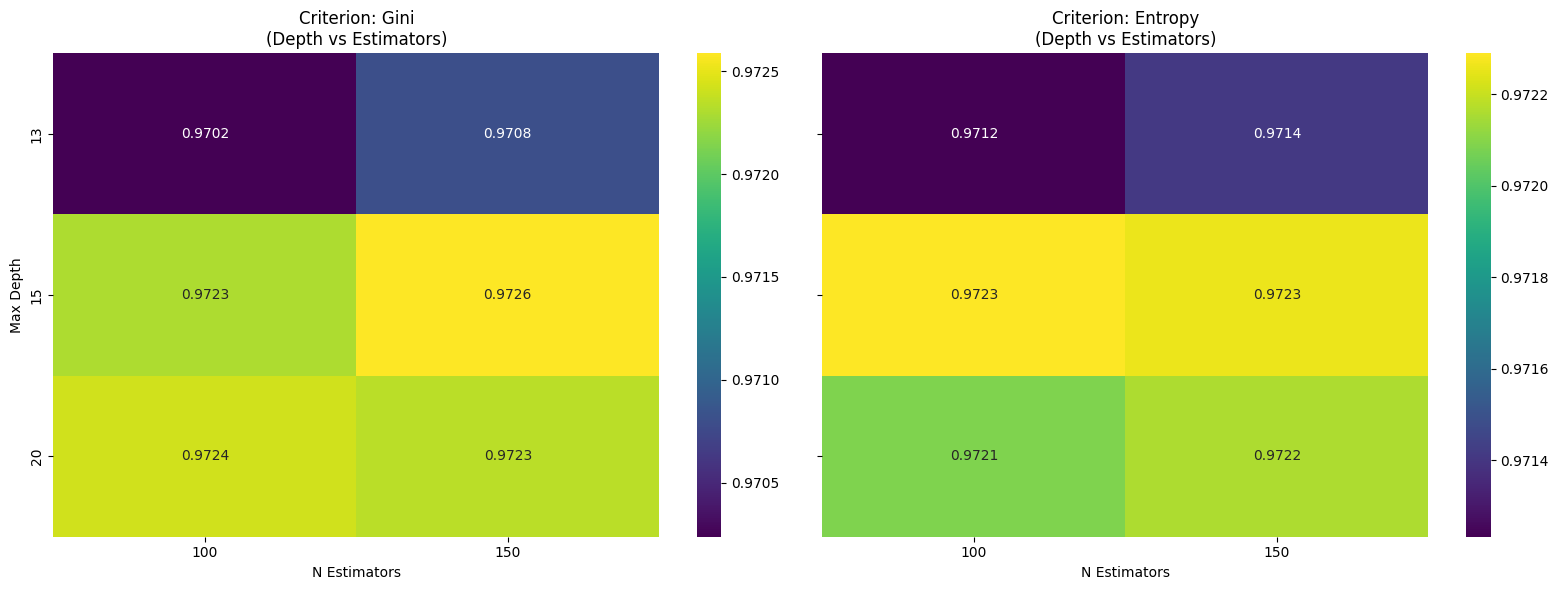

In [ ]:
# Convert cv_results to DataFrame
results_df = pd.DataFrame(grid_search.cv_results_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Data for Gini
pivot_gini = results_df[results_df['param_criterion'] == 'gini'].pivot_table(
    values='mean_test_f1', 
    index='param_max_depth', 
    columns='param_n_estimators',
    aggfunc='mean'
)

# Data for Entropy
pivot_entropy = results_df[results_df['param_criterion'] == 'entropy'].pivot_table(
    values='mean_test_f1', 
    index='param_max_depth', 
    columns='param_n_estimators',
    aggfunc='mean'
)

# Heatmap 1: Gini
sns.heatmap(pivot_gini, annot=True, cmap='viridis', fmt='.4f', ax=ax1)
ax1.set_title('Criterion: Gini\n(Depth vs Estimators)')
ax1.set_ylabel('Max Depth')
ax1.set_xlabel('N Estimators')

# Heatmap 2: Entropy
sns.heatmap(pivot_entropy, annot=True, cmap='viridis', fmt='.4f', ax=ax2)
ax2.set_title('Criterion: Entropy\n(Depth vs Estimators)')
ax2.set_ylabel('')
ax2.set_xlabel('N Estimators')

plt.tight_layout()
plt.show()

/var/folders/gn/jtqc266x2bd177vtp_xjv7vm0000gn/T/ipykernel_67700/3262188361.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='param_max_depth', y='mean_test_f1', data=results_df, palette="Set3")


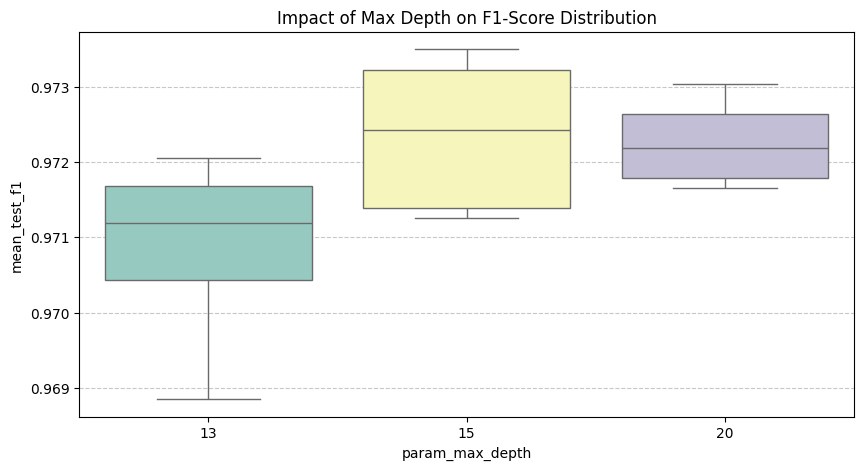

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='param_max_depth', y='mean_test_f1', data=results_df, palette="Set3")
plt.title('Impact of Max Depth on F1-Score Distribution')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

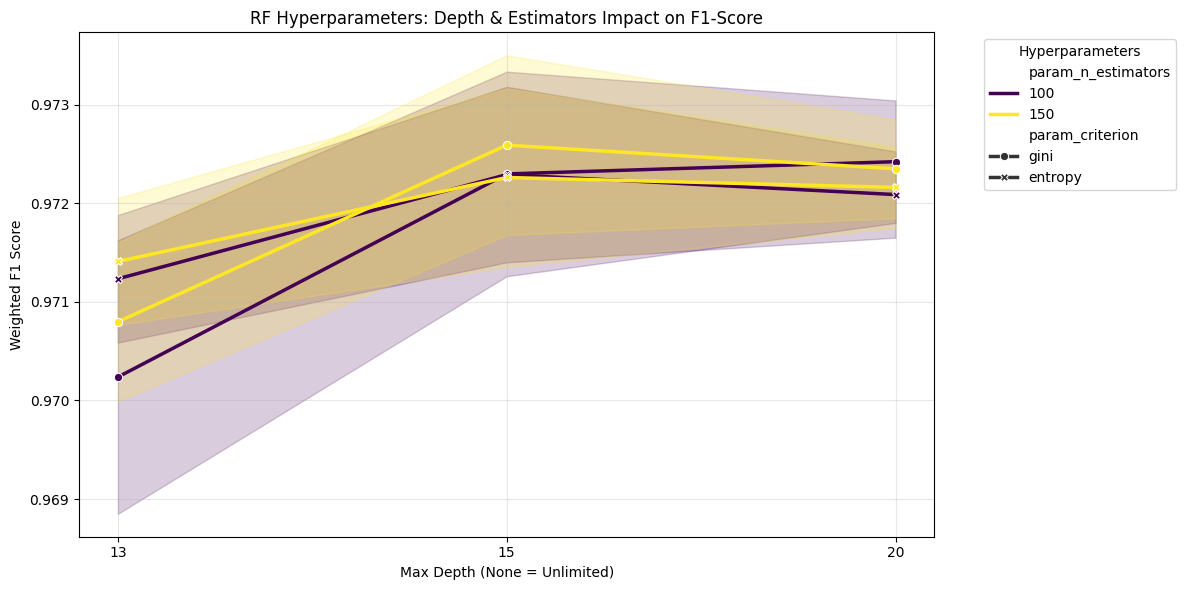

In [ ]:
# 1. Convert Grid Search Results to a DataFrame
results_df = pd.DataFrame(grid_search_result.cv_results_)

# 2. Filter/Clean specific columns for plotting
plot_df = results_df[[
    'param_max_depth',
    'param_n_estimators',
    'param_criterion',
    'mean_test_accuracy',
    'mean_test_f1'
]].copy()

# 'max_depth' contains None replaced with the string "None"
# so it can be plotted as a category.
plot_df['param_max_depth'] = plot_df['param_max_depth'].fillna('None').astype(str)

# 3. Create the Visualization
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=plot_df,
    x='param_max_depth',
    y='mean_test_f1',
    hue='param_n_estimators', # Color lines by number of trees
    style='param_criterion',  # Vary line style by Gini vs Entropy
    markers=True,
    dashes=False,
    palette='viridis',
    linewidth=2.5,
    err_style='band' # Shows the range/confidence interval for the hidden parameter (min_samples_leaf)
)

plt.title('RF Hyperparameters: Depth & Estimators Impact on F1-Score')
plt.xlabel('Max Depth (None = Unlimited)')
plt.ylabel('Weighted F1 Score')
plt.grid(True, alpha=0.3)

plt.legend(title='Hyperparameters', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Best validation score: 0.973570 using {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 1, 'n_estimators': 150}


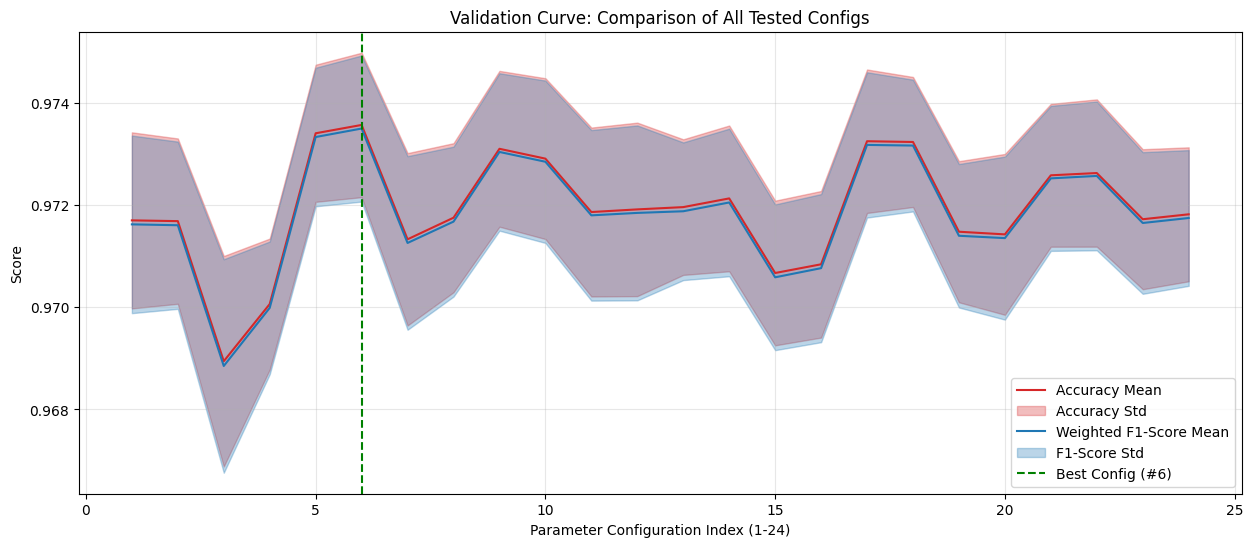

In [12]:
# 1. Print Best Result
print("Best validation score: %f using %s" % (grid_search_result.best_score_, grid_search_result.best_params_))

# 2. Extract Results
acc_means = grid_search_result.cv_results_['mean_test_accuracy']
acc_stds = grid_search_result.cv_results_['std_test_accuracy']
f1_means = grid_search_result.cv_results_['mean_test_f1']
f1_stds = grid_search_result.cv_results_['std_test_f1']
params = grid_search_result.cv_results_['params']

# 3. Plotting
plt.figure(figsize = (15, 6))
x = range(1, len(params) + 1) # X-axis is just the index of the combination (1 to 24)

# Plot Accuracy (Red)
plt.plot(x, acc_means, color = 'tab:red', label = 'Accuracy Mean')
plt.fill_between(x, acc_means + acc_stds, acc_means - acc_stds, alpha=0.3, color = 'tab:red', label = 'Accuracy Std')

# Plot F1-Score (Blue)
plt.plot(x, f1_means, color = 'tab:blue', label = 'Weighted F1-Score Mean')
plt.fill_between(x, f1_means + f1_stds, f1_means - f1_stds, alpha=0.3, color = 'tab:blue', label = 'F1-Score Std')

# Add a marker for the Best Parameter Configuration
best_index = grid_search_result.best_index_ + 1
plt.axvline(best_index, color='green', linestyle='--', label=f'Best Config (#{best_index})')

plt.xlabel('Parameter Configuration Index (1-24)')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.title("Validation Curve: Comparison of All Tested Configs")
plt.grid(True, alpha=0.3)
plt.show()

## Learning Curve

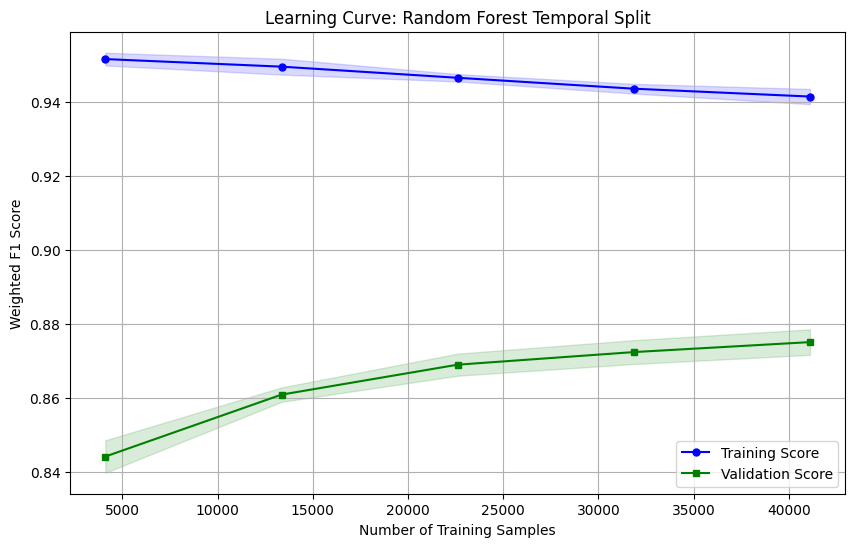

In [ ]:
# 1. Setup Parameters
# Prendiamo il miglior Random Forest trovato dalla Grid Search
best_model = grid_search_result.best_estimator_


train_sizes = np.linspace(0.1, 1.0, 5)

train_sizes_abs, train_scores, test_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    train_sizes=train_sizes,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_weighted',
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# 4. Plotting
plt.figure(figsize=(10, 6))

# Plot Training Score
plt.plot(train_sizes_abs, train_mean, color='blue', marker='o', markersize=5, label='Training Score')
plt.fill_between(train_sizes_abs, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

# Plot Validation Score
plt.plot(train_sizes_abs, test_mean, color='green', marker='s', markersize=5, label='Validation Score')
plt.fill_between(train_sizes_abs, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

# Formatting
plt.title('Learning Curve: Random Forest Temporal Split')
plt.xlabel('Number of Training Samples')
plt.ylabel('Weighted F1 Score')
plt.grid(True)
plt.legend(loc='lower right')

plt.show()

Generating predictions with best Random Forest model...

--- Random Forest Test Set Report Grid Search ---
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      1132
    ddos_dns       0.99      0.92      0.95      1074
   ddos_ldap       0.81      0.70      0.75      1186
  ddos_mssql       0.64      0.68      0.66      1183
ddos_netbios       0.99      0.99      0.99      1166
    ddos_ntp       0.89      0.99      0.94       198
   ddos_snmp       1.00      1.00      1.00      1197
   ddos_ssdp       0.82      0.91      0.86      1194
    ddos_syn       0.98      0.92      0.95      1096
   ddos_tftp       0.92      0.98      0.95      1053
    ddos_udp       0.55      0.56      0.55      1176
ddos_udp_lag       0.56      0.56      0.56      1198

    accuracy                           0.84     12853
   macro avg       0.85      0.85      0.85     12853
weighted avg       0.84      0.84      0.84     12853



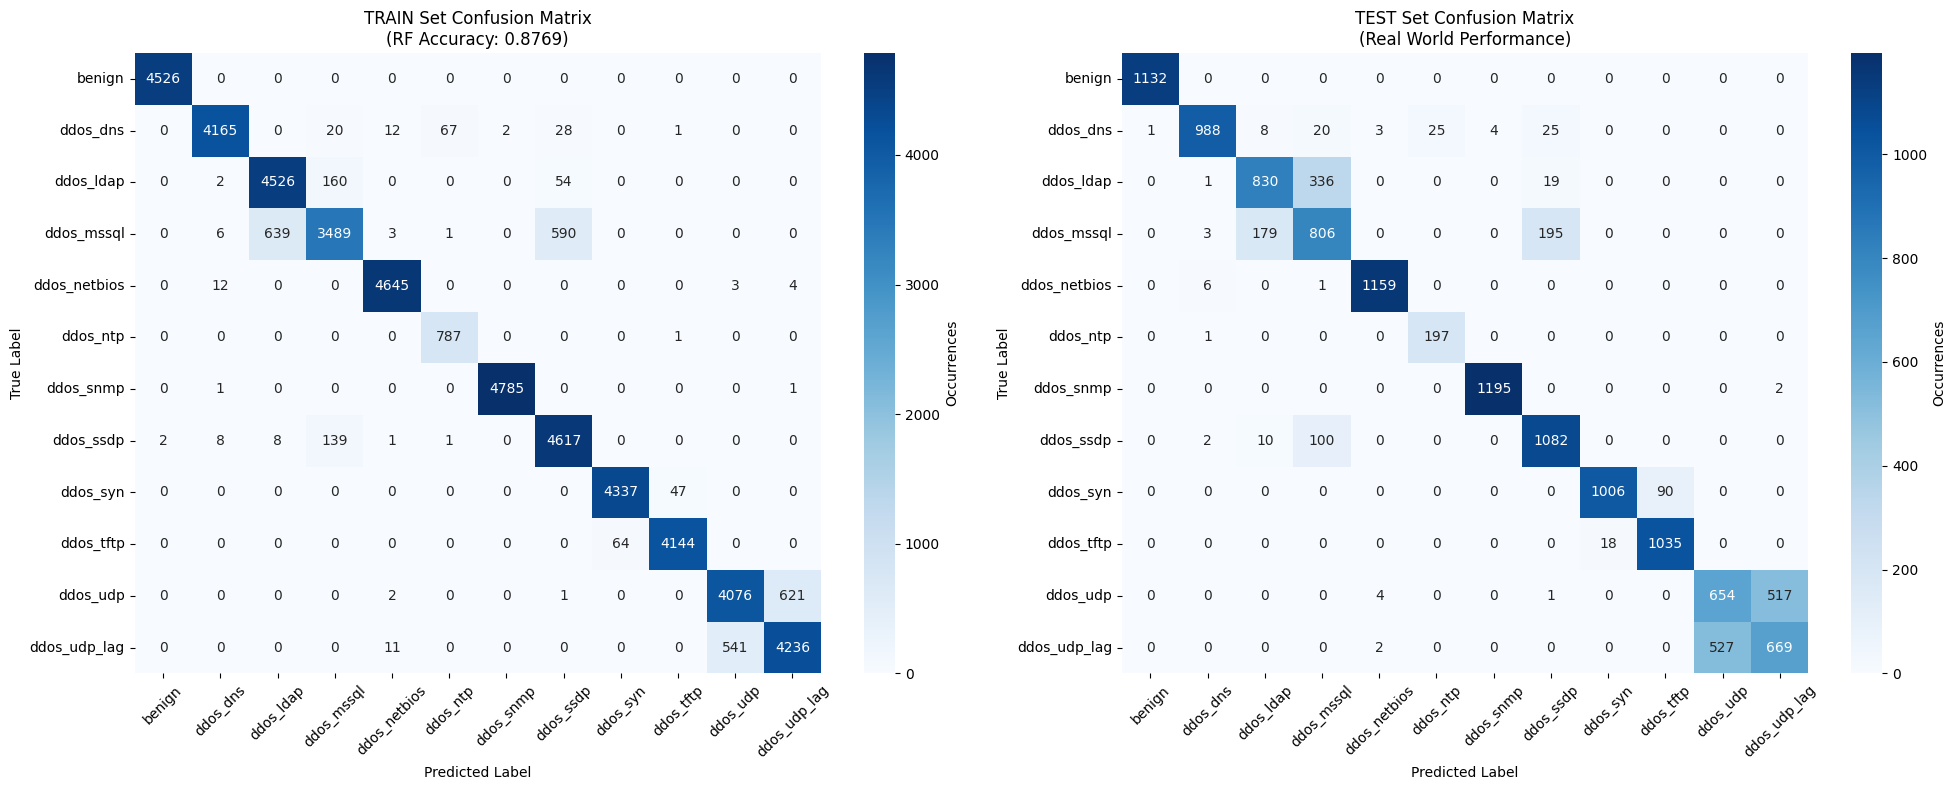

In [ ]:
best_model = grid_search_result.best_estimator_

# 2. Genera le previsioni
print("Generating predictions with best Random Forest model...")
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

# 3. Report testuali (Precision, Recall, F1)
#print('--- Random Forest Training Set Report Grid Search ---')
#print(classification_report(y_train, y_train_pred))
print('\n--- Random Forest Test Set Report Grid Search ---')
print(classification_report(y_test, y_test_pred))

# 4. Calcola le matrici di confusione
confusion_train = confusion_matrix(y_train, y_train_pred)
confusion_test = confusion_matrix(y_test, y_test_pred)

class_names = best_model.classes_

# 5. Plot Side-by-Side (Stile richiesto)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# --- Plot Train (Sinistra) ---
sns.heatmap(
    confusion_train,
    cmap='Blues',
    annot=True,
    cbar_kws={'label':'Occurrences'},
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_title(f'TRAIN Set Confusion Matrix\n(RF Accuracy: {grid_search_result.best_score_:.4f})')
axes[0].tick_params(axis='x', rotation=45) 

# --- Plot Test (Destra) ---
sns.heatmap(
    confusion_test,
    cmap='Blues',
    annot=True,
    cbar_kws={'label':'Occurrences'},
    fmt='d',
    xticklabels=class_names, 
    yticklabels=class_names, 
    ax=axes[1]
)
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].set_title('TEST Set Confusion Matrix\n(Real World Performance)')
axes[1].tick_params(axis='x', rotation=45) 

plt.tight_layout()
plt.show()

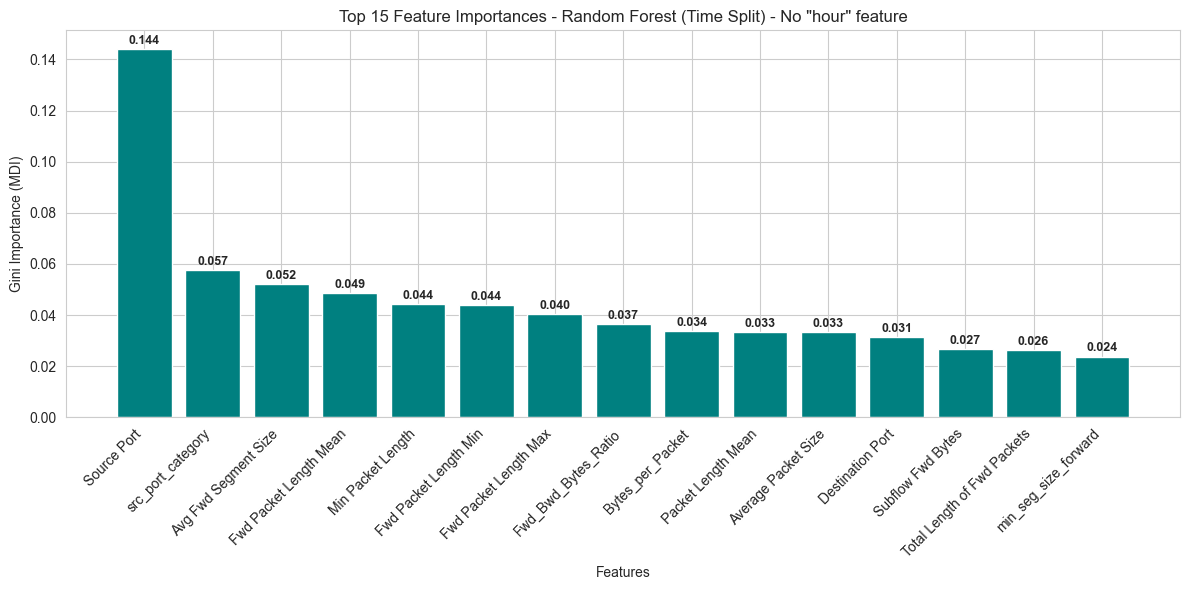

In [8]:
feature_names_ts = X_train_temp.columns
importances_ts = best_rf_model.feature_importances_
top_n = 15
# Sort indices from highest to lowest importance
indices_ts = np.argsort(importances_ts)[::-1][:top_n] 

# 2. Plotting (Vertical Layout)
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")

plt.bar(range(top_n), importances_ts[indices_ts], color='teal', align='center')
plt.xticks(range(top_n), [feature_names_ts[i] for i in indices_ts], rotation=45, ha='right')

# Add numerical labels on top of bars
for i, value in enumerate(importances_ts[indices_ts]):
    plt.text(i, value + 0.002, f'{value:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.ylabel("Gini Importance (MDI)")
plt.xlabel("Features")
plt.title(f"Top {top_n} Feature Importances - Random Forest (Time Split) - No \"hour\" feature")
plt.tight_layout()
plt.show()